In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split, Subset
import numpy as np
import matplotlib.pyplot as plt
import pathlib


In [3]:
import urllib.request
import tarfile

url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"

urllib.request.urlretrieve(url, "flower_photos.tgz")

with tarfile.open("flower_photos.tgz", "r:gz") as tar:
    tar.extractall(path="/content", filter="data")

data_dir = pathlib.Path("/content/flower_photos")

print("Dataset loaded successfully!")

Dataset loaded successfully!


## Dataset Description

For this assignment, I used the TensorFlow Flowers dataset. It contains 3,670 images from five flower classes: daisy, dandelion, roses, sunflowers, and tulips.

I divided the dataset into three parts:
- Training: 2,569 images (70%)
- Validation: 550 images (15%)
- Testing: 551 images (15%)

All images were resized to 32×32 pixels. I also used random horizontal flipping and rotation for training data augmentation.

In [4]:
full_data = datasets.ImageFolder(data_dir)

print("Total Images:", len(full_data))
print("Total Classes:", len(full_data.classes))
print("Class Names:", full_data.classes)

for class_name in full_data.classes:
    class_path = data_dir / class_name
    image_count = len(list(class_path.glob("*.jpg")))
    print(class_name, ":", image_count)

Total Images: 3670
Total Classes: 5
Class Names: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
daisy : 633
dandelion : 898
roses : 641
sunflowers : 699
tulips : 799


## Data Preprocessing and Augmentation

I resized the images to 32×32 pixels and converted them into tensors. For the training data, I used random horizontal flipping and rotation to add variation to the images.

I did not use random augmentation for validation and testing so that the model could be evaluated consistently.

In [5]:
size = 32

train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

In [23]:

full_data = datasets.ImageFolder(data_dir)


train_size = int(0.70 * len(full_data))
val_size = int(0.15 * len(full_data))
test_size = len(full_data) - train_size - val_size


train_split, val_split, test_split = random_split(
    full_data,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)


train_folder = datasets.ImageFolder(
    data_dir, transform=train_transform
)

test_folder = datasets.ImageFolder(
    data_dir, transform=test_transform
)

train_data = Subset(train_folder, train_split.indices)
val_data = Subset(test_folder, val_split.indices)
test_data = Subset(test_folder, test_split.indices)

print("Training Images:", len(train_data))
print("Validation Images:", len(val_data))
print("Testing Images:", len(test_data))

Training Images: 2569
Validation Images: 550
Testing Images: 551


In [7]:
batch_size = 32

trn_dl = DataLoader(
    train_data,
    batch_size=batch_size,
    shuffle=True
)

val_dl = DataLoader(
    val_data,
    batch_size=batch_size,
    shuffle=False
)

test_dl = DataLoader(
    test_data,
    batch_size=batch_size,
    shuffle=False
)

print("Training Batches:", len(trn_dl))
print("Validation Batches:", len(val_dl))
print("Testing Batches:", len(test_dl))

Training Batches: 81
Validation Batches: 18
Testing Batches: 18


## Custom CNN Architecture

I built a custom CNN model using PyTorch and `nn.Sequential()`.

The model has three convolutional layers with 16, 32, and 64 output channels. Each convolutional layer is followed by ReLU and MaxPooling.

After the convolutional layers, I used Flatten to convert the feature maps into a one-dimensional vector. Then I used two fully connected layers for classification.

The final layer has five outputs because the dataset contains five flower classes.

The model has 287,269 trainable parameters.

In [8]:
def get_model():
    model = nn.Sequential(
        nn.Conv2d(3, 16, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        nn.Conv2d(16, 32, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2, 2),

        nn.Flatten(),

        nn.Linear(64 * 4 * 4, 256),
        nn.ReLU(),

        nn.Linear(256, 5)
    )

    return model

In [9]:
device = "cuda" if torch.cuda.is_available() else "cpu"

model = get_model().to(device)

print(model)

total_params = sum(p.numel() for p in model.parameters())

print("\nTotal Parameters:", total_params)

Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Flatten(start_dim=1, end_dim=-1)
  (10): Linear(in_features=1024, out_features=256, bias=True)
  (11): ReLU()
  (12): Linear(in_features=256, out_features=5, bias=True)
)

Total Parameters: 287269


In [10]:
!pip -q install torchinfo

from torchinfo import summary

summary(
    model,
    input_size=(1, 3, 32, 32)
)

Layer (type:depth-idx)                   Output Shape              Param #
Sequential                               [1, 5]                    --
├─Conv2d: 1-1                            [1, 16, 32, 32]           448
├─ReLU: 1-2                              [1, 16, 32, 32]           --
├─MaxPool2d: 1-3                         [1, 16, 16, 16]           --
├─Conv2d: 1-4                            [1, 32, 16, 16]           4,640
├─ReLU: 1-5                              [1, 32, 16, 16]           --
├─MaxPool2d: 1-6                         [1, 32, 8, 8]             --
├─Conv2d: 1-7                            [1, 64, 8, 8]             18,496
├─ReLU: 1-8                              [1, 64, 8, 8]             --
├─MaxPool2d: 1-9                         [1, 64, 4, 4]             --
├─Flatten: 1-10                          [1, 1024]                 --
├─Linear: 1-11                           [1, 256]                  262,400
├─ReLU: 1-12                             [1, 256]                  --
├─

## Hyperparameters and Training Setup

I used the following settings to train my CNN model:

- **Image Size:** 32×32 pixels, to reduce computation.
- **Batch Size:** 32, to process images in small groups.
- **Epochs:** 10, to train the model multiple times.
- **Learning Rate:** 0.001, as a starting learning rate for Adam.
- **Optimizer:** Adam, to update model weights.
- **Loss Function:** CrossEntropyLoss, for five-class classification.
- **Activation Function:** ReLU, to help the model learn complex patterns.

I selected these settings to keep the model simple and suitable for this assignment.

In [11]:
learning_rate = 0.001
epoch_number = 10

loss_fn = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate
)

print("Loss Function:", loss_fn)
print("Optimizer: Adam")
print("Learning Rate:", learning_rate)
print("Epochs:", epoch_number)

Loss Function: CrossEntropyLoss()
Optimizer: Adam
Learning Rate: 0.001
Epochs: 10


In [14]:
def batch_accuracy(prediction, y):
    predicted_class = prediction.argmax(dim=1)
    accuracy = (predicted_class == y).float().mean()
    return accuracy.item()


def train_batch(x, y, model, optimizer, loss_fn):
    model.train()

    prediction = model(x)
    loss = loss_fn(prediction, y)
    accuracy = batch_accuracy(prediction, y)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    return loss.item(), accuracy


def train_one_epoch(model, trn_dl, optimizer, loss_fn):
    losses = []
    accuracies = []

    for x, y in trn_dl:
        x = x.to(device)
        y = y.to(device)

        loss, accuracy = train_batch(
            x, y, model, optimizer, loss_fn
        )

        losses.append(loss)
        accuracies.append(accuracy)

    return np.mean(losses), np.mean(accuracies)


def validation(model, val_dl, loss_fn):
    model.eval()

    losses = []
    accuracies = []

    with torch.no_grad():
        for x, y in val_dl:
            x = x.to(device)
            y = y.to(device)

            prediction = model(x)
            loss = loss_fn(prediction, y)
            accuracy = batch_accuracy(prediction, y)

            losses.append(loss.item())
            accuracies.append(accuracy)

    return np.mean(losses), np.mean(accuracies)

In [26]:
train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

for epoch in range(epoch_number):

    train_loss, train_acc = train_one_epoch(
        model, trn_dl, optimizer, loss_fn
    )

    val_loss, val_acc = validation(
        model, val_dl, loss_fn
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1}/{epoch_number}")
    print(f"Train Loss: {train_loss:.4f}, Train Accuracy: {train_acc*100:.2f}%")
    print(f"Val Loss: {val_loss:.4f}, Val Accuracy: {val_acc*100:.2f}%")
    print("-" * 50)

Epoch 1/10
Train Loss: 0.8487, Train Accuracy: 66.01%
Val Loss: 0.8912, Val Accuracy: 65.97%
--------------------------------------------------
Epoch 2/10
Train Loss: 0.8385, Train Accuracy: 65.97%
Val Loss: 0.9176, Val Accuracy: 63.89%
--------------------------------------------------
Epoch 3/10
Train Loss: 0.8051, Train Accuracy: 68.05%
Val Loss: 0.8844, Val Accuracy: 66.72%
--------------------------------------------------
Epoch 4/10
Train Loss: 0.7803, Train Accuracy: 68.36%
Val Loss: 0.8722, Val Accuracy: 67.77%
--------------------------------------------------
Epoch 5/10
Train Loss: 0.7724, Train Accuracy: 69.48%
Val Loss: 0.8552, Val Accuracy: 67.77%
--------------------------------------------------
Epoch 6/10
Train Loss: 0.7471, Train Accuracy: 70.48%
Val Loss: 0.8697, Val Accuracy: 65.68%
--------------------------------------------------
Epoch 7/10
Train Loss: 0.7507, Train Accuracy: 69.69%
Val Loss: 0.8674, Val Accuracy: 66.55%
-------------------------------------------

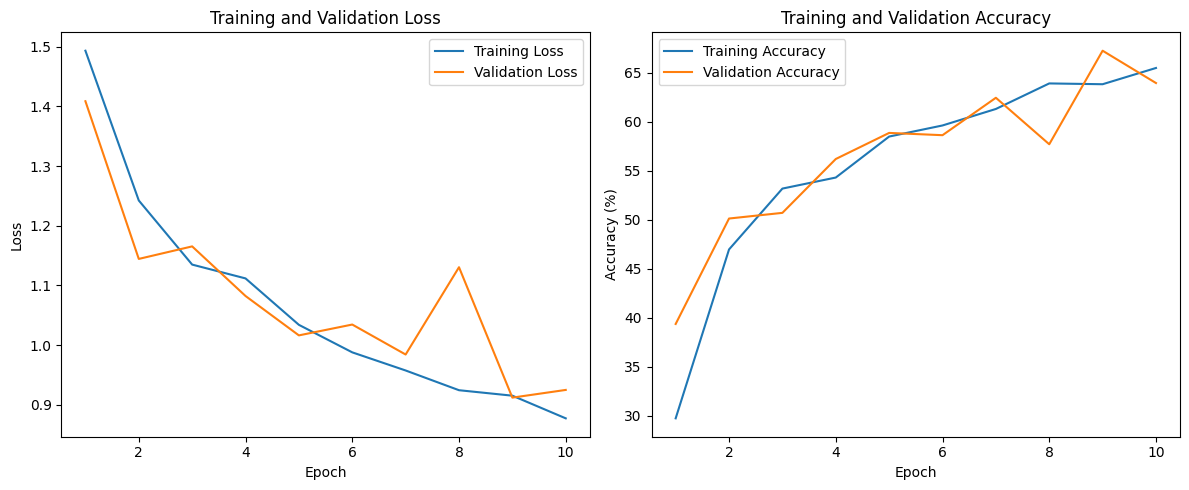

In [25]:
epochs = range(1, epoch_number + 1)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label="Training Loss")
plt.plot(epochs, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, np.array(train_accuracies) * 100,
         label="Training Accuracy")
plt.plot(epochs, np.array(val_accuracies) * 100,
         label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.tight_layout()
plt.show()

### Training and Validation Curve Analysis

The training loss decreased from 1.4934 to 0.8771, while the validation loss decreased from 1.4088 to 0.9247.

Training accuracy increased from 29.72% to 65.48%. Validation accuracy reached its highest value of 67.25% at epoch 9 and ended at 63.95%.

The graphs show that the model improved during training. Validation performance fluctuated slightly, but there was no large gap between training and validation accuracy at the final epoch.

In [24]:
test_loss, test_acc = validation(
    model, test_dl, loss_fn
)
print("Test Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_acc * 100, 2), "%")

Test Loss: 0.8514
Test Accuracy: 65.58 %


In [18]:
torch.save(model.state_dict(), "flower_cnn.pth")

print("Model saved successfully!")

Model saved successfully!


In [19]:
import os

model_size = os.path.getsize("flower_cnn.pth") / (1024 * 1024)

print("Model File: flower_cnn.pth")
print("Model Size:", round(model_size, 2), "MB")

Model File: flower_cnn.pth
Model Size: 1.1 MB


In [20]:
from google.colab import files

files.download("flower_cnn.pth")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
loaded_model = get_model().to(device)

loaded_model.load_state_dict(
    torch.load(
        "flower_cnn.pth",
        map_location=device,
        weights_only=True
    )
)

loaded_model.eval()

print("Model loaded successfully!")

Model loaded successfully!


In [22]:
from sklearn.metrics import classification_report, confusion_matrix

all_predictions = []
all_labels = []

loaded_model.eval()

with torch.no_grad():
    for x, y in test_dl:
        x = x.to(device)

        prediction = loaded_model(x)
        predicted_class = prediction.argmax(dim=1)

        all_predictions.extend(predicted_class.cpu().tolist())
        all_labels.extend(y.tolist())

correct = sum(
    p == y for p, y in zip(all_predictions, all_labels)
)

total = len(all_labels)
accuracy = correct / total * 100

print("Total Test Images:", total)
print("Correct Predictions:", correct)
print("Exact Test Accuracy:", round(accuracy, 2), "%")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=full_data.classes,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))

Total Test Images: 551
Correct Predictions: 367
Exact Test Accuracy: 66.61 %

Classification Report:
              precision    recall  f1-score   support

       daisy       0.72      0.68      0.70        91
   dandelion       0.56      0.84      0.67       119
       roses       0.66      0.52      0.58        92
  sunflowers       0.82      0.66      0.73       116
      tulips       0.67      0.60      0.63       133

    accuracy                           0.67       551
   macro avg       0.69      0.66      0.66       551
weighted avg       0.68      0.67      0.67       551


Confusion Matrix:
[[ 62  19   6   1   3]
 [  7 100   2   8   2]
 [  4  14  48   0  26]
 [  7  23   0  77   9]
 [  6  22  17   8  80]]


## Analysis and Discussion of Results

I trained a custom CNN model using the TensorFlow Flowers dataset. The dataset contains 3,670 images from five flower classes. I used 70% of the images for training, 15% for validation, and the remaining images for testing.

After training for 10 epochs, the training accuracy reached 65.48%, while the validation accuracy reached 63.95%. The training and validation losses decreased overall, which shows that the model was learning useful image features.

On the test dataset, the model correctly classified 367 out of 551 images, achieving an accuracy of 66.61%.

Among the five classes, sunflowers had the highest F1-score of 0.73, while roses had the lowest F1-score of 0.58. The confusion matrix shows that some flower classes were difficult for the model to distinguish.

The results are reasonable for a small custom CNN trained on 32×32 images. However, the model still makes classification errors, so there is room for improvement.

## Conclusion and Future Work

In this assignment, I developed a custom CNN model for classifying five different types of flowers using PyTorch.

The model was trained using the Adam optimizer and CrossEntropyLoss. After 10 epochs, the model achieved 66.61% test accuracy.

This assignment helped me understand image preprocessing, CNN architecture, model training, validation, testing, and saving trained model weights.

### Future Work

In the future, the model could be improved by:

- Using larger input images.
- Increasing the number of training epochs.
- Trying different CNN architectures.
- Adjusting the learning rate.
- Improving data augmentation.